# Chronic Kidney Disease Prediction
**Author:** Anesu Rirwa

**Question:** Can routine clinical measurements identify patients with chronic kidney disease (CKD), and how few tests are needed to do it reliably?

**Data:** UCI Chronic Kidney Disease dataset (public on Kaggle): 400 patients, 24 clinical measurements (blood tests, urine tests, blood pressure, history) and a CKD / not-CKD label.

**Why this dataset needs care:** it is small, messy (stray tabs and `?` values) and contains two traps that make models look better than they are. Section 3 shows both.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, recall_score, precision_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from xgboost import XGBClassifier

RANDOM_STATE = 42
pd.set_option("display.width", 140)

## 1. Load and clean

In [2]:
raw = pd.read_csv("kidney_disease.csv")
print(raw.shape)

df = raw.copy()
text_cols = df.select_dtypes(exclude="number").columns
for c in text_cols:
    # Remove stray tabs/spaces and treat '?' as missing
    df[c] = df[c].astype("string").str.replace("\t", "", regex=False).str.strip().replace({"?": pd.NA, "": pd.NA})

# Three numeric columns were stored as text because of the bad entries
for c in ["pcv", "wc", "rc"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

print(df["classification"].value_counts())
df.head()

(400, 26)
classification
ckd       250
notckd    150
Name: count, dtype: Int64


,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,classification
0,0,48.0,80.0,1.020,1.0,0.0,<NA>,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,<NA>,normal,notpresent,notpresent,...,38,6000,<NA>,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,<NA>,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd


In [3]:
column_names = {
    "age": "age", "bp": "blood pressure", "sg": "urine specific gravity", "al": "urine albumin",
    "su": "urine sugar", "rbc": "red blood cells (urine)", "pc": "pus cells", "pcc": "pus cell clumps",
    "ba": "bacteria", "bgr": "blood glucose", "bu": "blood urea", "sc": "serum creatinine",
    "sod": "sodium", "pot": "potassium", "hemo": "haemoglobin", "pcv": "packed cell volume",
    "wc": "white cell count", "rc": "red cell count", "htn": "hypertension", "dm": "diabetes",
    "cad": "coronary artery disease", "appet": "appetite", "pe": "pedal oedema", "ane": "anaemia",
}
y = (df["classification"] == "ckd").astype(int)
numeric = ["age", "bp", "sg", "al", "su", "bgr", "bu", "sc", "sod", "pot", "hemo", "pcv", "wc", "rc"]
categorical = ["rbc", "pc", "pcc", "ba", "htn", "dm", "cad", "appet", "pe", "ane"]
for c in categorical:
    df[c] = df[c].astype(object).where(df[c].notna(), np.nan)

print("Missing values (% of rows), top 8:")
print((df[numeric + categorical].isna().mean() * 100).round(1).sort_values(ascending=False).head(8))

Missing values (% of rows), top 8:
rbc     38.0
rc      32.8
wc      26.5
pot     22.0
sod     21.8
pcv     17.8
pc      16.2
hemo    13.0
dtype: float64


## 2. Exploration

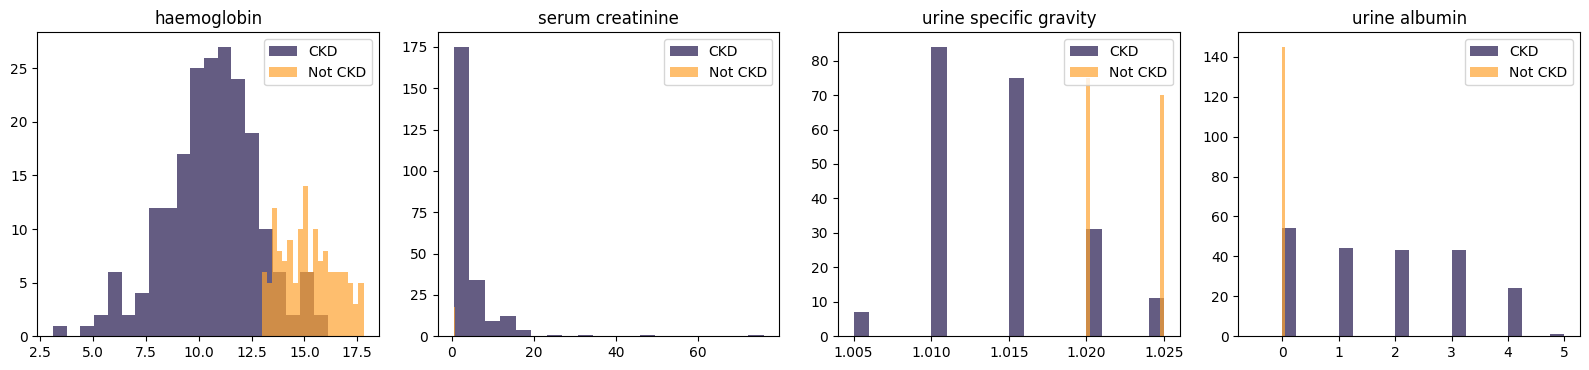

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, col in zip(axes, ["hemo", "sc", "sg", "al"]):
    for label, colour in [(1, "#22174D"), (0, "#FEA330")]:
        ax.hist(df.loc[y == label, col].dropna(), bins=20, alpha=0.7, color=colour,
                label="CKD" if label else "Not CKD")
    ax.set_title(column_names[col]); ax.legend()
plt.tight_layout(); plt.show()

**Observation:** haemoglobin, serum creatinine, urine specific gravity and urine albumin separate the two groups almost completely. That is medically sensible (kidney damage lowers haemoglobin and raises creatinine and albumin), and it means very high accuracy is expected.

## 3. Two traps that inflate results
**Trap 1: the row ID.** The data is sorted: IDs 0-249 are all CKD and 250-399 are all healthy. Leaving `id` in would give a "perfect" model that has learned nothing medical. It is dropped.

**Trap 2: missing values carry the label.** CKD patients have far more missing tests than healthy ones, probably because the two groups were collected differently. A model could learn "lots of missing tests = sick".

In [5]:
print(df.groupby("classification")["id"].agg(["min", "max"]))

n_missing = df[numeric + categorical].isna().sum(axis=1)
print()
print("Average number of missing tests per patient:")
print(n_missing.groupby(df["classification"]).mean().round(2))

# How far does the missing-count alone get us?
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
acc = cross_validate(LogisticRegression(), n_missing.to_frame(), y, cv=cv, scoring=["accuracy"])["test_accuracy"].mean()
print(f"\nAccuracy using ONLY the number of missing tests: {acc:.3f}  (always-CKD baseline: {y.mean():.3f})")

                min  max
classification          
ckd               0  249
notckd          250  399

Average number of missing tests per patient:
classification
ckd       3.63
notckd    0.69
dtype: float64

Accuracy using ONLY the number of missing tests: 0.790  (always-CKD baseline: 0.625)


**Result:** the count of missing tests alone predicts CKD well above the baseline. To make sure the models below learn from the measurements and not from missingness, missing values are filled with the median (numbers) or most common value (categories) **without** adding missing-value indicator columns, and all filling is done inside the pipeline using training data only.

## 4. Train/test split and model comparison

In [6]:
X = df[numeric + categorical]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

def make_preprocess(num_cols, cat_cols):
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_cols),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
    ])

models = {
    "Always CKD (baseline)": DummyClassifier(strategy="most_frequent"),
    "Logistic regression": LogisticRegression(max_iter=1000, C=0.3),
    "Random forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.05, eval_metric="logloss",
                             random_state=RANDOM_STATE),
}
rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", make_preprocess(numeric, categorical)), ("model", model)])
    s = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["accuracy", "recall", "precision", "roc_auc"])
    rows.append({"Model": name, "Accuracy": s["test_accuracy"].mean(), "Recall (CKD caught)": s["test_recall"].mean(),
                 "Precision": s["test_precision"].mean(), "ROC-AUC": s["test_roc_auc"].mean()})
pd.DataFrame(rows).set_index("Model").round(3)

,Accuracy,Recall (CKD caught),Precision,ROC-AUC
Model,,,,
Always CKD (baseline),0.627,1.000,0.627,0.500
Logistic regression,0.997,0.995,1.000,1.000
Random forest,0.990,0.995,0.989,1.000
XGBoost,0.990,0.989,0.995,0.999


**Recall is the key metric here.** Missing a CKD patient (a false negative) is far more costly than sending a healthy person for a follow-up test, so the aim is to catch as many CKD cases as possible.

## 5. How few tests are needed?

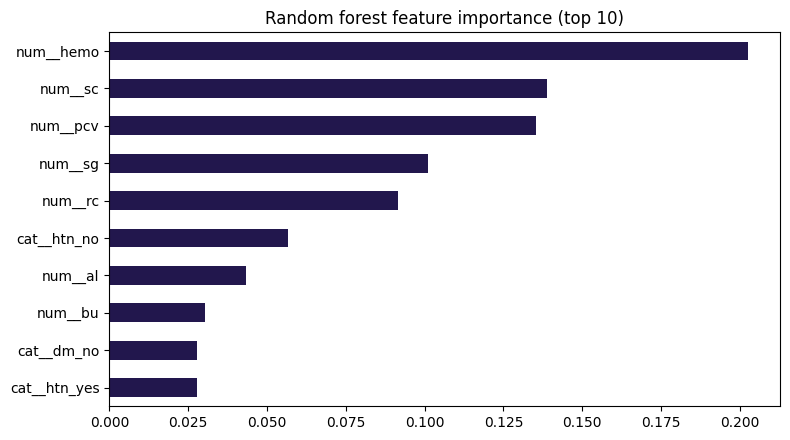

In [7]:
rf = Pipeline([("prep", make_preprocess(numeric, categorical)),
               ("model", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE))]).fit(X_train, y_train)
names = rf.named_steps["prep"].get_feature_names_out()
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=names).sort_values(ascending=False)
imp.head(10).sort_values().plot(kind="barh", figsize=(8, 4.5), color="#22174D")
plt.title("Random forest feature importance (top 10)"); plt.tight_layout(); plt.show()

In [8]:
small_panel = ["hemo", "sc", "sg", "al"]   # haemoglobin, serum creatinine, urine specific gravity, urine albumin
small = Pipeline([("prep", make_preprocess(small_panel, [])), ("model", LogisticRegression(max_iter=1000, C=0.3))])
s = cross_validate(small, X_train[small_panel], y_train, cv=cv, scoring=["accuracy", "recall", "roc_auc"])
print("4-test logistic regression (cross-validation):",
      {k.replace('test_', ''): round(v.mean(), 3) for k, v in s.items() if k.startswith("test_")})

4-test logistic regression (cross-validation): {'accuracy': np.float64(0.977), 'recall': np.float64(0.979), 'roc_auc': np.float64(0.996)}


**Result:** a simple logistic regression using just four routine tests performs close to the full 24-measurement models. That matters in practice: it suggests a cheap screening rule built from one blood test and one urine test.

## 6. Final evaluation on the held-out test set

Test accuracy: 0.970   Recall: 0.968   Precision: 0.984   ROC-AUC: 0.999

              precision    recall  f1-score   support

     Not CKD      0.949     0.974     0.961        38
         CKD      0.984     0.968     0.976        62

    accuracy                          0.970       100
   macro avg      0.966     0.971     0.968       100
weighted avg      0.970     0.970     0.970       100



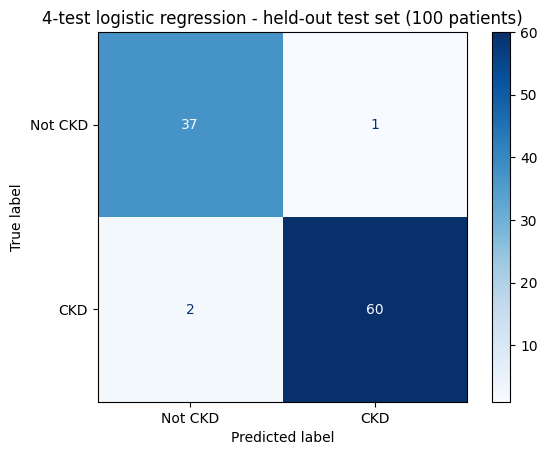

Coefficients (positive = higher CKD risk):
haemoglobin              -2.21
serum creatinine          0.92
urine specific gravity   -1.49
urine albumin             1.23
dtype: float64


In [9]:
final = Pipeline([("prep", make_preprocess(small_panel, [])), ("model", LogisticRegression(max_iter=1000, C=0.3))])
final.fit(X_train[small_panel], y_train)
proba = final.predict_proba(X_test[small_panel])[:, 1]
pred = (proba >= 0.5).astype(int)
print(f"Test accuracy: {accuracy_score(y_test, pred):.3f}   Recall: {recall_score(y_test, pred):.3f}   "
      f"Precision: {precision_score(y_test, pred):.3f}   ROC-AUC: {roc_auc_score(y_test, proba):.3f}")
print()
print(classification_report(y_test, pred, target_names=["Not CKD", "CKD"], digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=["Not CKD", "CKD"]).plot(cmap="Blues")
plt.title("4-test logistic regression - held-out test set (100 patients)"); plt.show()

coef = pd.Series(final.named_steps["model"].coef_[0], index=[column_names[c] for c in small_panel]).round(2)
print("Coefficients (positive = higher CKD risk):"); print(coef)

## 7. Conclusions and limitations
- **A four-test screen works on this data.** Haemoglobin, serum creatinine, urine specific gravity and urine albumin give near-perfect separation, and the coefficient directions match clinical knowledge (low haemoglobin and high creatinine and albumin mean higher risk).
- **Near-perfect scores are a warning, not a victory.** This dataset is small (400 patients), comes from a single source, and has two leakage traps (row order and missingness). Results on new hospitals would almost certainly be lower.
- **Next step before any real use:** validate on data from a different clinic, and check performance on early-stage CKD, which is the clinically useful case and is harder to detect than advanced disease.